In [2]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
df.describe()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [5]:
print(df.columns.tolist())

['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [6]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [7]:
df.columns = df.columns.str.strip()

# Remove duplicate IDs if available, otherwise exact duplicate rows
if "show_id" in df.columns:
    df = df.drop_duplicates(subset="show_id").copy()
else:
    df = df.drop_duplicates().copy()

# Trim extra spaces in text columns
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    df[col] = df[col].str.strip()

# Parse dates and years
if "date_added" in df.columns:
    df["date_added"] = pd.to_datetime(df["date_added"], errors="coerce")

if "release_year" in df.columns:
    df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce").astype("Int64")

# Keep missing values clear instead of guessing their contents
for col in ["director", "cast", "country", "rating", "duration", "listed_in"]:
    if col in df.columns:
        df[col] = df[col].fillna("Not listed")

print("Shape after cleaning:", df.shape)
display(df.isna().sum().sort_values(ascending=False).to_frame("remaining missing"))

Shape after cleaning: (8807, 12)


C:\Users\shivani.dharmjidnyas\AppData\Local\Temp\ipykernel_15856\3937511005.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df.select_dtypes(include="object").columns


,remaining missing
date_added,10
show_id,0
title,0
type,0
director,0
cast,0
country,0
release_year,0
rating,0
duration,0


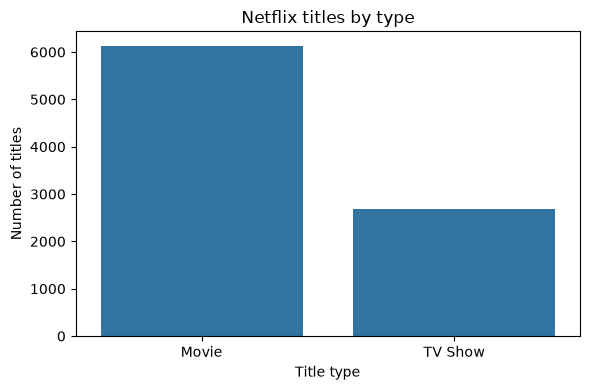

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="type", order=df["type"].value_counts().index)
plt.title("Netflix titles by type")
plt.xlabel("Title type")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

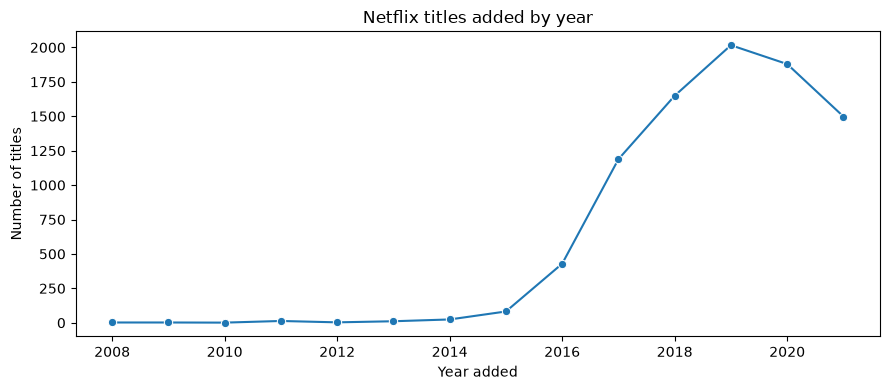

In [9]:
added = df.dropna(subset=["date_added"]).copy()
added["year_added"] = added["date_added"].dt.year

year_counts = added["year_added"].value_counts().sort_index()

plt.figure(figsize=(9, 4))
sns.lineplot(x=year_counts.index, y=year_counts.values, marker="o")
plt.title("Netflix titles added by year")
plt.xlabel("Year added")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

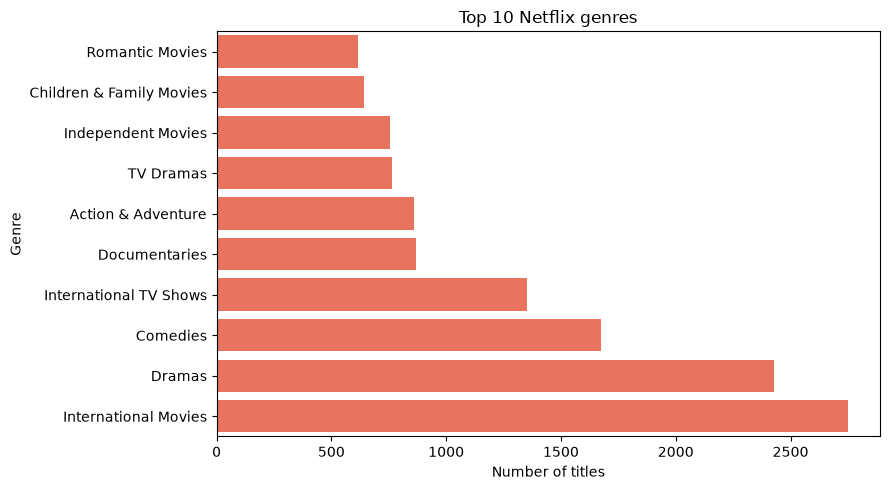

In [11]:
genres = (
    df.loc[df["listed_in"] != "Not listed", "listed_in"]
      .str.split(", ")
      .explode()
      .value_counts()
      .head(10)
      .sort_values()
)

plt.figure(figsize=(9, 5))
sns.barplot(x=genres.values, y=genres.index, color="tomato")
plt.title("Top 10 Netflix genres")
plt.xlabel("Number of titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()